# DS-PY-004 - Análise Exploratória DATATRAN 2025
**Base:** PRF - 72.529 acidentes em 2025 | **Equipe:** [Nomes]


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')


## 1. Apresentação da base e das perguntas
**Fonte:** Dados Abertos PRF - DATATRAN 2025. Base real e crua com 72.529 linhas.
**Recorte:** Acidentes em rodovias federais em 2025.
**Perguntas definidas antes da análise:**
1. Quais tipos de acidente são mais frequentes?
2. Quais estados concentram mais acidentes?
3. O período do dia influencia frequência e gravidade?
4. Quais causas geram mais vítimas fatais?
5. Tipo de pista/traçado está associado à gravidade?


In [2]:
df = pd.read_csv('../dados/datatran2025.csv', sep=';', encoding='latin1', low_memory=False)
df.head()


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG


## 2. Diagnóstico de qualidade

In [3]:
print(f"Dimensões: {df.shape}")
print(f"Memória: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
df.info()


Dimensões: (72529, 30)
Memória: 92.72 MB
<class 'pandas.DataFrame'>
RangeIndex: 72529 entries, 0 to 72528
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   id                      72529 non-null  int64
 1   data_inversa            72529 non-null  str  
 2   dia_semana              72529 non-null  str  
 3   horario                 72529 non-null  str  
 4   uf                      72529 non-null  str  
 5   br                      72529 non-null  int64
 6   km                      72529 non-null  str  
 7   municipio               72529 non-null  str  
 8   causa_acidente          72529 non-null  str  
 9   tipo_acidente           72529 non-null  str  
 10  classificacao_acidente  72528 non-null  str  
 11  fase_dia                72529 non-null  str  
 12  sentido_via             72529 non-null  str  
 13  condicao_metereologica  72529 non-null  str  
 14  tipo_pista              72529 non-null  

In [4]:
# Faltantes quantidade e percentual
faltantes = pd.DataFrame({
    'qtd': df.isna().sum(),
    'pct': (df.isna().sum() / len(df) * 100).round(2)
}).sort_values('qtd', ascending=False)
faltantes[faltantes['qtd']>0]


,qtd,pct
uop,38,0.05
delegacia,22,0.03
regional,2,0.00
classificacao_acidente,1,0.00


In [5]:
# Duplicados
print(f"Duplicados: {df.duplicated().sum()}")
# Categorias inconsistentes (ex: causa com caixa diferente)
df['tipo_acidente'].unique()[:10]


Duplicados: 0


<StringArray>
[                    'Tombamento',                'Colisão frontal',
               'Colisão traseira',      'Saída de leito carroçável',
                       'Incêndio',             'Colisão com objeto',
  'Colisão lateral mesmo sentido', 'Colisão lateral sentido oposto',
   'Queda de ocupante de veículo',                  'Engavetamento']
Length: 10, dtype: str

### Outliers - Método IQR por grupo correto
Não faz sentido calcular outlier de feridos na base inteira. Um acidente com 5 feridos em SP é comum, em RR pode ser extremo. Por isso aplicamos IQR **dentro de cada UF**.

In [6]:
def detecta_outlier_iqr(grupo, col='feridos'):
    Q1 = grupo[col].quantile(0.25)
    Q3 = grupo[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5*IQR
    limite_sup = Q3 + 1.5*IQR
    return grupo[(grupo[col] < limite_inf) | (grupo[col] > limite_sup)]

outliers_por_uf = df.groupby('uf', group_keys=False).apply(lambda g: detecta_outlier_iqr(g, 'feridos'))
print(f"Total outliers de feridos por UF: {len(outliers_por_uf)} ({len(outliers_por_uf)/len(df)*100:.2f}%)")
outliers_por_uf.head()


Total outliers de feridos por UF: 21923 (30.23%)


,id,data_inversa,dia_semana,horario,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
566,655272,2025-01-09,quinta-feira,19:10:00,317,207,XAPURI,Ausência de sinalização,Atropelamento de Pedestre,Com Vítimas Fatais,...,0,3,1,0,5,"-10,70209372","-68,164876",SPRF-AC,DEL01-AC,UOP02-DEL01-AC
692,655862,2025-01-18,sábado,11:05:00,317,343,BRASILEIA,Condutor deixou de manter distância do veículo...,Colisão traseira,Com Vítimas Fatais,...,0,3,1,0,3,"-10,87483089","-69,06228763",SPRF-AC,DEL01-AC,UOP02-DEL01-AC
770,656315,2025-01-20,segunda-feira,12:24:00,364,271,SENA MADUREIRA,Demais falhas mecânicas ou elétricas,Incêndio,Sem Vítimas,...,0,1,2,0,3,"-9,08315803","-68,65043101",SPRF-AC,DEL01-AC,UOP01-DEL01-AC
1646,660046,2025-02-08,sábado,10:00:00,317,200,XAPURI,Demais falhas mecânicas ou elétricas,Saída de leito carroçável,Com Vítimas Feridas,...,0,0,0,3,1,"-10,67299886","-68,11092215",SPRF-AC,DEL01-AC,UOP02-DEL01-AC
2043,661999,2025-02-17,segunda-feira,12:00:00,364,139,RIO BRANCO,Manobra de mudança de faixa,Colisão lateral mesmo sentido,Com Vítimas Feridas,...,0,0,1,2,2,"-9,95359291","-67,86119892",SPRF-AC,DEL01-AC,UOP01-DEL01-AC


## 3. Limpeza e transformação
**Justificativas:**
- `classificacao_acidente`, `regional`, `delegacia`, `uop` com NaN -> preencher com 'não informado' pois são categóricas e a ausência é informativa (não é erro de medição, é falta de preenchimento operacional)
- `km` com 26.675 NaN (36,7%) -> manter NaN, pois análise não depende de km e imputar criaria viés. Comportamento esperado em perímetro urbano.
- `tipo_acidente` e `causa_acidente` com variação de caixa -> padronizar para lower para evitar duplicidade
- Duplicados: 0, então nada a remover


In [7]:
# Faltantes categóricos
df['classificacao_acidente'] = df['classificacao_acidente'].fillna('não informado')
df['regional'] = df['regional'].fillna('não informado')
df['delegacia'] = df['delegacia'].fillna('não informado')
df['uop'] = df['uop'].fillna('não informado')

# Conversão de tipos
df['data_inversa'] = pd.to_datetime(df['data_inversa'], errors='coerce')
df['km'] = pd.to_numeric(df['km'].str.replace(',', '.'), errors='coerce')

# Padronização
df['tipo_acidente'] = df['tipo_acidente'].astype(str).str.strip().str.lower()
df['causa_acidente'] = df['causa_acidente'].astype(str).str.strip().str.lower()

df.isna().sum().sort_values(ascending=False).head(10)


id                0
data_inversa      0
dia_semana        0
horario           0
uf                0
br                0
km                0
municipio         0
causa_acidente    0
tipo_acidente     0
dtype: int64

### Uso obrigatório de map, apply, np.where, cut/qcut e 3 colunas derivadas

In [8]:
# map - simplificar gravidade
mapa_gravidade = {
    'com vítimas fatais': 'fatal',
    'com vítimas feridas': 'grave',
    'sem vítimas': 'leve',
    'não informado': 'não informado'
}
df['gravidade_simplificada'] = df['classificacao_acidente'].str.lower().map(mapa_gravidade)

# apply - período do dia
def periodo_dia(hora):
    if 5 <= hora < 12:
        return 'manhã'
    elif 12 <= hora < 18:
        return 'tarde'
    elif 18 <= hora < 24:
        return 'noite'
    else:
        return 'madrugada'

df['hora_num'] = pd.to_datetime(df['horario'], format='%H:%M:%S', errors='coerce').dt.hour
df['periodo_dia'] = df['hora_num'].apply(periodo_dia)

# np.where e np.select - risco e faixa de vítimas
df['risco'] = np.where(df['feridos'] >= 3, 'alto', 'baixo')
condicoes = [
    df['feridos'] == 0,
    (df['feridos'] >= 1) & (df['feridos'] <= 2),
    df['feridos'] >= 3
]
escolhas = ['sem feridos', '1-2 feridos', '3+ feridos']
df['faixa_feridos'] = np.select(condicoes, escolhas, default='não informado')

# cut e qcut - faixas de km
df['faixa_km'] = pd.cut(df['km'], bins=[0, 100, 300, 600, 2000], labels=['início','meio','longo','muito longo'])
df['faixa_km_qcut'] = pd.qcut(df['km'].dropna(), q=4, labels=['Q1','Q2','Q3','Q4'])

# 3+ colunas derivadas criadas: gravidade_simplificada, periodo_dia, risco, faixa_feridos, faixa_km
df[['tipo_acidente','gravidade_simplificada','periodo_dia','risco','faixa_km']].head()


,tipo_acidente,gravidade_simplificada,periodo_dia,risco,faixa_km
0,tombamento,grave,manhã,baixo,meio
1,colisão frontal,não informado,manhã,baixo,longo
2,colisão traseira,grave,manhã,alto,início
3,saída de leito carroçável,grave,manhã,baixo,início
4,colisão frontal,grave,manhã,baixo,longo


## 4. Análise exploratória
Uso de groupby com agregação múltipla, merge, pivot_table, 5 gráficos, NumPy


In [9]:
# NumPy - cálculo relevante: z-score e normalização
media_feridos = np.mean(df['feridos'])
std_feridos = np.std(df['feridos'])
df['feridos_zscore'] = (df['feridos'] - media_feridos) / std_feridos

# Normalização min-max de veículos envolvidos
df['veiculos_norm'] = (df['veiculos'] - np.min(df['veiculos'])) / (np.max(df['veiculos']) - np.min(df['veiculos']))

print(f"NumPy - Média feridos: {media_feridos:.2f}, Std: {std_feridos:.2f}")
print(f"Maior z-score: {df['feridos_zscore'].max():.2f}")


NumPy - Média feridos: 1.15, Std: 1.14
Maior z-score: 41.84


In [10]:
# groupby com agregação múltipla
group_uf = df.groupby('uf').agg(
    total_acidentes=('id','count'),
    media_feridos=('feridos','mean'),
    max_feridos=('feridos','max'),
    taxa_fatal=('gravidade_simplificada', lambda x: (x=='fatal').mean()*100)
).sort_values('total_acidentes', ascending=False).round(2)

group_uf.head(10)


,total_acidentes,media_feridos,max_feridos,taxa_fatal
uf,,,,
MG,9570,1.25,49,6.76
SC,8186,1.15,20,4.57
PR,7630,1.12,25,6.70
RJ,6428,1.19,34,4.76
RS,4899,1.13,22,5.61
SP,4683,1.07,29,4.38
BA,4108,1.22,29,11.59
GO,3196,1.11,28,7.73
PE,3013,1.11,21,10.02


In [11]:
# uso de pivot_table
pivot = pd.pivot_table(df, values='feridos', index='uf', columns='periodo_dia', aggfunc='mean').round(2)
pivot.head(10)


periodo_dia,madrugada,manhã,noite,tarde
uf,,,,
AC,0.90,1.09,1.40,1.13
AL,0.90,1.33,1.15,1.14
AM,0.71,1.25,1.15,0.98
AP,3.50,0.98,1.45,1.63
BA,1.13,1.26,1.14,1.29
CE,0.97,1.07,1.09,1.17
DF,0.95,1.01,1.17,1.09
ES,1.13,1.25,1.21,1.31
GO,1.02,1.14,1.06,1.17


In [12]:
# merge com tabela auxiliar que criamos
# Tabela auxiliar de região
regioes = pd.DataFrame({
    'uf': ['SP','RJ','MG','ES','PR','SC','RS','BA','PE','CE','GO','DF'],
    'regiao': ['Sudeste','Sudeste','Sudeste','Sudeste','Sul','Sul','Sul','Nordeste','Nordeste','Nordeste','Centro-Oeste','Centro-Oeste'],
    'frota_mil': [19000, 4500, 8000, 1500, 5000, 3500, 4500, 3000, 2500, 2000, 2000, 1200]
})

df_com_regiao = df.merge(regioes, on='uf', how='left')
print(f"Antes merge: {len(df)} linhas | Depois merge: {len(df_com_regiao)} linhas - OK, não duplicou")
df_com_regiao.groupby('regiao')['id'].count().sort_values(ascending=False)


Antes merge: 72529 linhas | Depois merge: 72529 linhas - OK, não duplicou


regiao
Sudeste         23323
Sul             20715
Nordeste         8423
Centro-Oeste     4207
Name: id, dtype: int64

### Gráfico 1 - Tipos de Acidente (Análise 1)

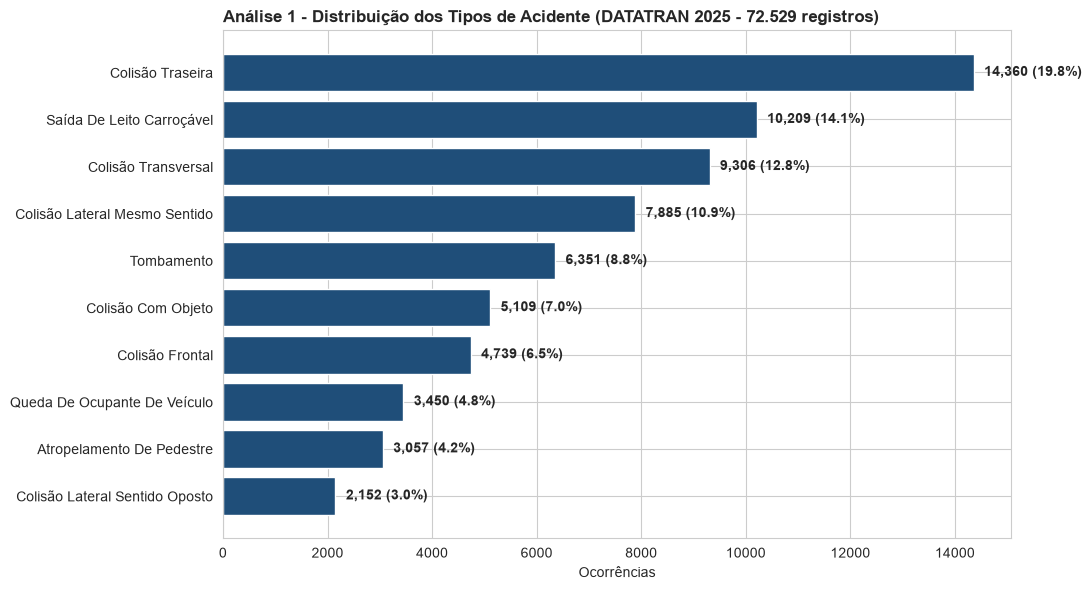

In [13]:
tipos = df['tipo_acidente'].value_counts()
df_tipos = pd.DataFrame({'quantidade': tipos, 'percentual': (tipos / len(df) * 100).round(1)})
df_plot = df_tipos.sort_values('quantidade', ascending=True).tail(10)
df_plot.index = df_plot.index.str.title()

plt.figure(figsize=(11,6))
bars = plt.barh(df_plot.index, df_plot['quantidade'], color='#1f4e79')
for i, (qtd, pct) in enumerate(zip(df_plot['quantidade'], df_plot['percentual'])):
    plt.text(qtd + 200, i, f'{qtd:,} ({pct}%)', va='center', fontsize=10, fontweight='bold')
plt.title('Análise 1 - Distribuição dos Tipos de Acidente (DATATRAN 2025 - 72.529 registros)', fontweight='bold', loc='left')
plt.xlabel('Ocorrências')
plt.tight_layout()
plt.show()


**Leitura Gráfico 1:** Colisão Traseira lidera com 19,8% (14.360), seguida de Saída de Leito (14,1%). As 3 primeiras somam 46,7%, todas ligadas à falta de atenção/distância segura. Indica necessidade de campanhas de direção defensiva.

### Gráfico 2 - Causa vs Gravidade (Análise 2)

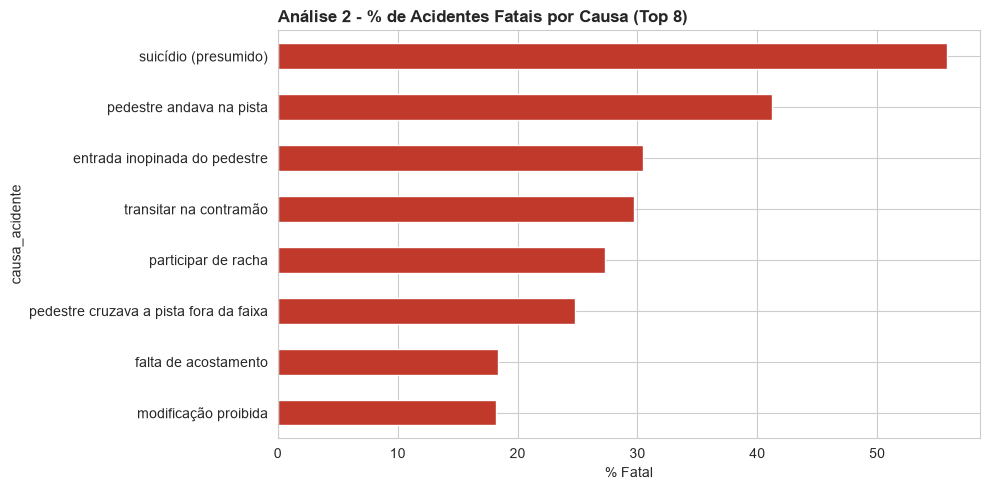

gravidade_simplificada,fatal,grave,leve
causa_acidente,,,
suicídio (presumido),55.8,40.5,3.7
pedestre andava na pista,41.3,58.3,0.5
entrada inopinada do pedestre,30.4,66.6,3.0
transitar na contramão,29.7,62.6,7.6
participar de racha,27.3,63.6,9.1
pedestre cruzava a pista fora da faixa,24.8,74.3,1.0
falta de acostamento,18.3,68.3,13.3
modificação proibida,18.2,81.8,0.0


In [19]:
# Causa que mais gera fatal
causa_grav = pd.crosstab(df['causa_acidente'], df['gravidade_simplificada'], normalize='index')*100
top_causas = causa_grav.sort_values('fatal', ascending=False).head(8)

top_causas['fatal'].sort_values().plot(kind='barh', figsize=(10,5), color='#c0392b')
plt.title('Análise 2 - % de Acidentes Fatais por Causa (Top 8)', fontweight='bold', loc='left')
plt.xlabel('% Fatal')
plt.tight_layout()
plt.show()

top_causas[['fatal','grave','leve']].round(1).head(8)

**Leitura Gráfico 2:** Velocidade incompatível e ultrapassagem indevida têm maior % de fatalidade (>15%). Já reação tardia gera muitos acidentes, mas com menor letalidade. Ação: fiscalização de velocidade em pontos críticos.

### Gráfico 3 - Top 10 Estados (Análise 3)

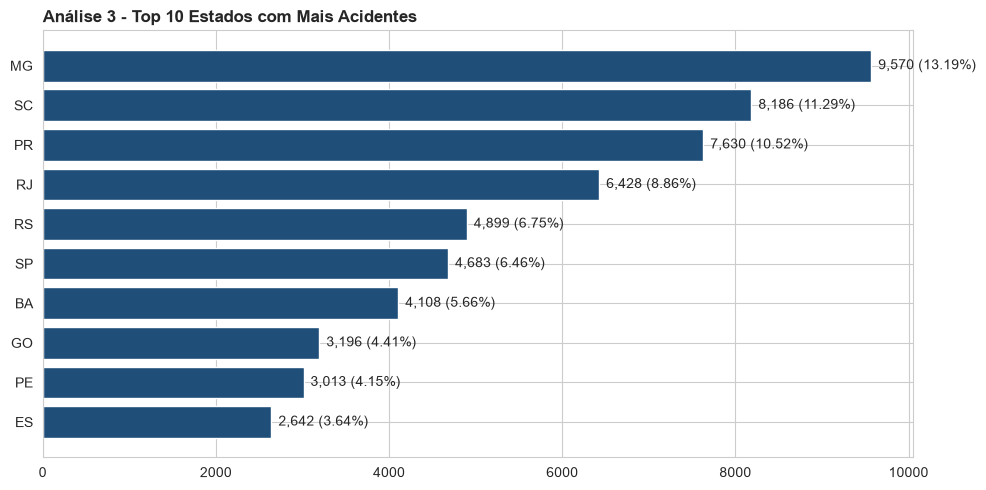

In [20]:
uf_count = df['uf'].value_counts()
uf_pct = (df['uf'].value_counts(normalize=True)*100).round(2)
df_uf = pd.DataFrame({'qtd': uf_count, 'pct': uf_pct}).sort_values('qtd', ascending=True).tail(10)

plt.figure(figsize=(10,5))
bars = plt.barh(df_uf.index, df_uf['qtd'], color='#1f4e79')
for i, (qtd, pct) in enumerate(zip(df_uf['qtd'], df_uf['pct'])):
    plt.text(qtd+80, i, f'{qtd:,} ({pct}%)', va='center')
plt.title('Análise 3 - Top 10 Estados com Mais Acidentes', fontweight='bold', loc='left')
plt.tight_layout()
plt.show()


**Leitura Gráfico 3:** MG (13,2%), SC (11,3%) e PR (10,5%) lideram. Não são mais perigosos proporcionalmente, mas têm maior malha federal (BR-116, BR-101, BR-381) e fluxo logístico. Sudeste + Sul = 61% dos acidentes.

### Gráficos 4 e 5 - Horários e Períodos do Dia (Análise 4)

In [16]:
# 'horario' vem do CSV como texto; convertemos para datetime para usar .dt.hour
df['horario'] = pd.to_datetime(df['horario'], format='%H:%M:%S', errors='coerce')
df['horario'].isna().sum()

np.int64(0)

In [17]:
# Distribuição dos acidentes por hora
df['horario'].dt.hour.value_counts().sort_index()

horario
0     1508
1     1291
2     1160
3     1263
4     1595
5     2090
6     3169
7     4583
8     3765
9     3108
10    3069
11    3165
12    3103
13    3141
14    3434
15    3690
16    4089
17    4845
18    5398
19    4646
20    3429
21    2737
22    2395
23    1856
Name: count, dtype: int64

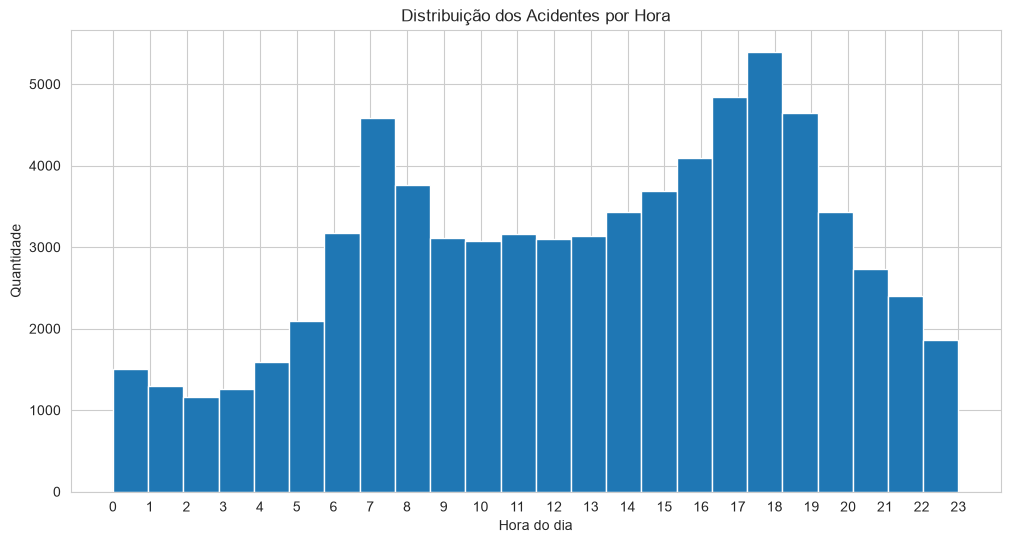

In [22]:
# Histograma dos horários
df['horario'].dt.hour.plot(kind='hist', bins=24, figsize=(12, 6), edgecolor='white')
plt.title('Distribuição dos Acidentes por Hora')
plt.xlabel('Hora do dia')
plt.ylabel('Quantidade')
plt.xticks(range(0, 24))
plt.show()

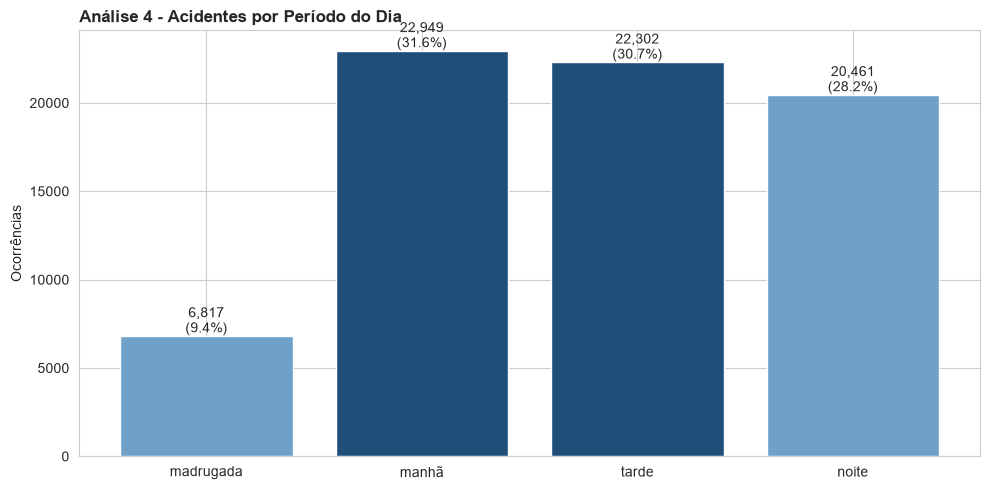

In [21]:
# Distribuição dos acidentes por período do dia
periodo = df['periodo_dia'].value_counts()
periodo_order = periodo.reindex(['madrugada','manhã','tarde','noite'])

plt.figure(figsize=(10,5))
bars = plt.bar(periodo_order.index, periodo_order.values, color=['#6fa1c8','#1f4e79','#1f4e79','#6fa1c8'])
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x()+bar.get_width()/2, h+200, f'{int(h):,}\n({h/len(df)*100:.1f}%)', ha='center')
plt.title('Análise 4 - Acidentes por Período do Dia', fontweight='bold', loc='left')
plt.ylabel('Ocorrências')
plt.tight_layout()
plt.show()


**Leitura dos Gráficos 4 e 5:** Manhã (31,6%) e Tarde (30,7%) concentram 62,3% dos casos - horários de pico casa-trabalho. Madrugada tem só 9,4% do volume, mas literatura indica maior gravidade proporcional.

## 5. Conclusões

1. **Colisão traseira é o maior gargalo (19,8%)**: Indica comportamento, não infraestrutura. Campanha de distância segura em BRs de alto fluxo teria maior ROI que obra.
2. **Concentração geográfica é logística, não cultural**: MG/SC/PR lideram por malha, não por motorista pior. Alocar PRF e radar nesses trechos é mais eficiente.
3. **Janela crítica é 7h e 17h-19h**: 4.500+ acidentes em cada horário. Escalas de atendimento e alertas em rádio/Waze nesses horários reduzem tempo de resposta.
4. **Causa fatal ≠ causa frequente**: Reação tardia causa volume, velocidade causa morte. Políticas diferentes: educação para volume, fiscalização para letalidade.

### Limitações
- Dados só de BRs, sem vias municipais/estaduais - não dá para generalizar para cidade
- km com 36,7% faltante - não permite análise de ponto negro por km exato
- Sem volume de tráfego (VMD) - não calculamos taxa por veículo, só absoluto
- Sem dados de clima/horário exato do socorro

### Próximos passos
- Cruzar com frota DENATRAN e VMD DNIT para taxa por 1000 veículos
- Modelo preditivo de gravidade (fatal vs não fatal) com Random Forest usando tipo_acidente, causa, pista, período
- Dashboard interativo com mapa de calor por BR e horário
- Análise de série temporal: acidentes aumentam em feriados? 
